# Variational Quantum Classifier PennyLane — Notebook unico finale

Questo notebook riunisce la pipeline sperimentale del progetto HPQC / Quantum Machine Learning per la classificazione binaria MNIST **4 vs 9** con dataset ridotto a **3 feature** e circuito a **3 qubit**.

L'obiettivo non è incollare i notebook precedenti, ma sostituirli con una struttura unica, parametrica e riproducibile:

- caricamento corretto del dataset;
- costruzione controllata di train/test e grading set bilanciato;
- definizione unica di feature map, ansatz, loss, ottimizzatori e metriche;
- inizializzazione uniforme piccola dei parametri dell'ansatz per tutti gli esperimenti confrontabili;
- gestione degli artefatti per evitare retraining inutili;
- tabella finale coerente e grafici di confronto.

La metrica principale è la **grading accuracy bilanciata**. Il test interno contiene solo 12 osservazioni e deve essere letto come controllo secondario, non come base conclusiva.

## 1. Audit dei notebook sorgente e decisioni metodologiche

Dall'audit dei notebook caricati emergono tre punti importanti.

1. **BASELINE00** ed **EXP02** risultano già aggiornati all'inizializzazione uniforme `uniform[-0.05,0.05]_seed10599`.
2. Diversi esperimenti successivi usano ancora `np.zeros(...)` o `onp.zeros(...)` per l'initial point. I risultati storici di questi notebook non devono essere mescolati con quelli aggiornati.
3. Il notebook caricato come **EXP09_ADAM_MSE_BASELINE_STRUCTURE** usa `ANSATZ_REPS = 6`, non 4. Quindi, se si vuole mantenere anche una variante Adam+MSE con `ANSATZ_REPS = 4`, questa va distinta da una variante supplementare `EXP09B_REPS6`.

Tabella sintetica dell'audit:

| Notebook sorgente | Stato inizializzazione | Nota critica |
|---|---:|---|
| `BASELINE00_PENNYLANE.ipynb` | uniforme piccola | Codice aggiornato, ma alcuni markdown storici parlano ancora di initial point nullo. |
| `VQC_EXP02_OPTIMIZER_COMPARISON_PENNYLANE..ipynb` | uniforme piccola | Aggiornato; include Adam, SPSA, L-BFGS-B. |
| `VQC_EXP03_ENCODING_LOCAL_RX_RZ_PENNYLANE.ipynb` | zero | Da rigenerare con inizializzazione uniforme. |
| `EXP04_ENCODING_FULL_PAIRWISE_CX_PENNYLANE_optimal_params.py` | non verificabile | Contiene solo pesi ottimali, senza metadata completi. Non usarlo come risultato confrontabile. |
| `VQC_EXP05_ADAM_LOCAL_RX_RZ_PENNYLANE.ipynb` | zero | Da rigenerare con inizializzazione uniforme. |
| `VQC_EXP06_MSE_LOSS_PennyLane.ipynb` | zero | Da rigenerare con inizializzazione uniforme. |
| `EXP07_COBYLA_ANSATZ_REPS6.ipynb` | zero | Da rigenerare con inizializzazione uniforme. |
| `EXP08_COBYLA_ANSATZ_REPS2.ipynb` | zero | Da rigenerare con inizializzazione uniforme. |
| `VQC_EXP09_ADAM_MSE_BASELINE_STRUCTURE_PennyLane.ipynb` | zero | In più contiene `ANSATZ_REPS = 6`: trattarlo come `EXP09B_REPS6`. |
| `EXP10_COBYLA_ANSATZ_REPS8.ipynb` | zero | Da rigenerare con inizializzazione uniforme. |
| `EXP11_FEATURE_REPS3.ipynb` | zero | Da rigenerare; inoltre il campo `EXPERIMENT_ID` nei risultati appare incoerente in alcune celle storiche. |

La tabella finale generata da questo notebook accetta come **pienamente confrontabili** solo risultati con metadata compatibili con l'inizializzazione uniforme fissata.

## 2. Setup tecnico

Il notebook usa PennyLane come unico framework operativo. Qiskit non viene usato nella pipeline finale.

La prima esecuzione può richiedere molto tempo se `RUN_TRAINING = True`. Per evitare retraining accidentali, il valore predefinito è `False`: il notebook carica gli artefatti già presenti e segnala gli esperimenti mancanti.

In [2]:
import json
import time
import warnings
from dataclasses import asdict, dataclass, field
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as onp
import pandas as pd
import requests
from scipy.optimize import minimize

import pennylane as qml
from pennylane import numpy as np

try:
    import plotly.express as px
    PLOTLY_AVAILABLE = True
except Exception:
    PLOTLY_AVAILABLE = False

warnings.filterwarnings("default")

## 3. Configurazione globale

Scelte fissate:

- `GLOBAL_SEED = 10598` per split e grading;
- `INIT_SEED = 10599` per l'inizializzazione dell'ansatz;
- `INIT_LOW = -0.05`, `INIT_HIGH = 0.05`;
- device PennyLane `default.qubit` con 3 qubit;
- grading set bilanciato 1000/1000.

L'inizializzazione uniforme non viene trattata come leva sperimentale: è parte del protocollo aggiornato e deve essere comune a tutti gli esperimenti confrontabili.

In [14]:
# ============================================================
# Modalità di esecuzione
# ============================================================

RUN_TRAINING = False
RETRAIN_IF_ARTIFACT_EXISTS = False

# Se True, il notebook scarica il dataset se non è presente localmente.
ALLOW_DATASET_DOWNLOAD = True

# Cartella unica degli artefatti del notebook finale.
ARTIFACT_ROOT = Path("final_vqc_artifacts")
FIGURE_ROOT = ARTIFACT_ROOT / "figures"
ARTIFACT_ROOT.mkdir(parents=True, exist_ok=True)
FIGURE_ROOT.mkdir(parents=True, exist_ok=True)

# ============================================================
# Costanti globali del progetto
# ============================================================

GLOBAL_SEED = 10598
INIT_SEED = 10599
INIT_LOW = -0.05
INIT_HIGH = 0.05
INITIALIZATION_NAME = "uniform[-0.05,0.05]_seed10599"

N_QUBITS = 3
CORPUS_PERCENTAGE = 4
TEST_PERCENTAGE = 5
GRADING_DATASET_SIZE = 2000
GRADING_PER_CLASS = GRADING_DATASET_SIZE // 2
EPS = 1e-10
PRINT_EVERY = 10

DATASET_URL = "https://gitlab.com/GlazeDonuts/vqc-datasets/-/raw/master/datasets/dataset_4_9.csv"
DATASET_PATH = Path("dataset_4_9.csv")

onp.random.seed(GLOBAL_SEED)
np.random.seed(GLOBAL_SEED)

print("RUN_TRAINING:", RUN_TRAINING)
print("RETRAIN_IF_ARTIFACT_EXISTS:", RETRAIN_IF_ARTIFACT_EXISTS)
print("Artifact root:", ARTIFACT_ROOT.resolve())
print("Initialization:", INITIALIZATION_NAME)

RUN_TRAINING: False
RETRAIN_IF_ARTIFACT_EXISTS: False
Artifact root: C:\Users\veron.PC-VERONICA\Desktop\Università\II anno\HPQC\progetto\MNIST\final_vqc_artifacts
Initialization: uniform[-0.05,0.05]_seed10599


## 4. Caricamento corretto del dataset

Il dataset atteso ha forma `(6000, 4)`.

La struttura corretta è:

```text
colonna 0       label MNIST originale, cioè 4 oppure 9
colonne 1,2,3   feature numeriche già ridotte
```

Non bisogna leggere `raw_data[:, :-1]` come feature, perché in questo dataset la label è nella prima colonna. Quell'errore inserirebbe la label originale 4/9 dentro le feature e produrrebbe data leakage.

In [15]:
def load_dataset(dataset_path=DATASET_PATH):
    dataset_path = Path(dataset_path)

    if not dataset_path.exists():
        if not ALLOW_DATASET_DOWNLOAD:
            raise FileNotFoundError(
                f"Dataset non trovato in {dataset_path}. "
                "Impostare ALLOW_DATASET_DOWNLOAD=True oppure copiare dataset_4_9.csv nella cartella del notebook."
            )
        response = requests.get(DATASET_URL, timeout=60)
        response.raise_for_status()
        dataset_path.write_bytes(response.content)

    raw = onp.loadtxt(dataset_path, delimiter=",")
    labels_original = raw[:, 0].astype(int)
    features = raw[:, 1:]
    labels_binary = onp.where(labels_original == 4, 0, 1).astype(int)
    return raw, features, labels_original, labels_binary


data, data_features, data_labels_original, data_labels = load_dataset(DATASET_PATH)

print("Dataset shape:", data.shape)
print("Feature shape:", data_features.shape)
print("Label originali:", onp.unique(data_labels_original))
print("Label binarie:", onp.unique(data_labels))

Dataset shape: (6000, 4)
Feature shape: (6000, 3)
Label originali: [4 9]
Label binarie: [0 1]


## 5. Controlli metodologici sul dataset

Questi assert sono volutamente rigidi: bloccano l'esecuzione se il dataset non rispetta il setup del progetto o se compare il bug di data leakage legato alla posizione della label.

In [16]:
def validate_dataset(raw, features, labels_original, labels_binary):
    assert raw.shape == (6000, 4), f"Shape dataset inattesa: {raw.shape}"
    assert features.shape[1] == N_QUBITS, f"Numero feature inatteso: {features.shape[1]}"
    assert set(onp.unique(labels_original).tolist()) == {4, 9}, "Le label originali devono essere solo 4 e 9."
    assert set(onp.unique(labels_binary).tolist()) == {0, 1}, "Le label binarie devono essere solo 0 e 1."
    assert not onp.isnan(raw).any(), "Il dataset contiene NaN."

    # Controlli anti-leakage specifici per l'errore di lettura della label.
    assert not onp.array_equal(features[:, 0], labels_original), (
        "Possibile data leakage: la prima feature coincide con la label originale."
    )
    assert not set(onp.unique(features[:, 0]).tolist()).issubset({4, 9}), (
        "Possibile data leakage: la prima feature contiene solo valori 4/9."
    )

    return True

validate_dataset(data, data_features, data_labels_original, data_labels)
print("Controlli dataset superati.")

Controlli dataset superati.


## 6. Visualizzazione dello spazio delle feature

Le tre feature sono coordinate latenti della rappresentazione ridotta. Non vanno interpretate direttamente come larghezza, altezza o spessore della cifra.

I grafici servono a verificare qualitativamente la separabilità delle classi. Una sovrapposizione nello spazio delle feature impone cautela: non tutto l'errore va attribuito al circuito o all'ottimizzatore.

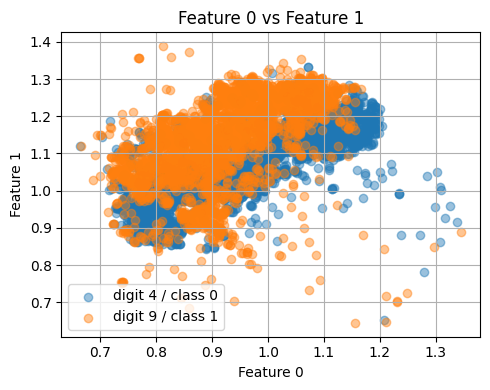

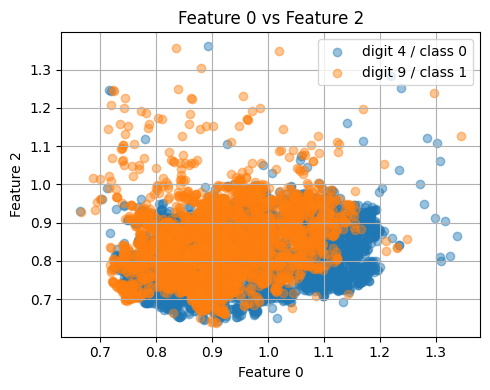

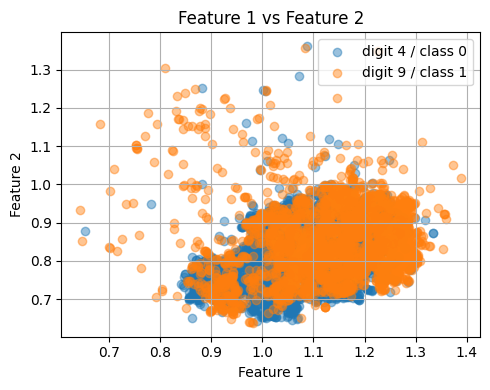

In [30]:
features_df = pd.DataFrame({
    "feature_0": data_features[:, 0],
    "feature_1": data_features[:, 1],
    "feature_2": data_features[:, 2],
    "label": data_labels.astype(int),
    "digit": data_labels_original.astype(int),
})

if PLOTLY_AVAILABLE:
    fig = px.scatter_3d(
        features_df,
        x="feature_0",
        y="feature_1",
        z="feature_2",
        color="label",
        title="MNIST 4 vs 9 ridotto a 3 feature",
    )
    fig.show()
else:
    print("Plotly non disponibile: salto lo scatter 3D interattivo.")

for i, j in [(0, 1), (0, 2), (1, 2)]:
    plt.figure(figsize=(5, 4))
    plt.scatter(data_features[data_labels == 0, i], data_features[data_labels == 0, j], alpha=0.45, label="digit 4 / class 0")
    plt.scatter(data_features[data_labels == 1, i], data_features[data_labels == 1, j], alpha=0.45, label="digit 9 / class 1")
    plt.xlabel(f"Feature {i}")
    plt.ylabel(f"Feature {j}")
    plt.title(f"Feature {i} vs Feature {j}")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

## 7. Split train/test bilanciato

Il corpus ridotto è il 4% del dataset, cioè 240 osservazioni: 120 per classe.

Il test interno è il 5% del corpus, cioè 12 osservazioni: 6 per classe. Il training contiene quindi 228 osservazioni.

Questo test è molto piccolo: è utile come controllo interno, ma non è statisticamente robusto. La valutazione principale è il grading set bilanciato.

In [47]:
def build_train_test_split(labels_original, labels_binary, features):
    corp_split = int(CORPUS_PERCENTAGE * features.shape[0] // 100)
    rng_split = onp.random.default_rng(GLOBAL_SEED)

    idx_digit_4_all = onp.where(labels_original == 4)[0]
    idx_digit_9_all = onp.where(labels_original == 9)[0]

    four_indices = rng_split.choice(idx_digit_4_all, corp_split // 2, replace=False)
    nine_indices = rng_split.choice(idx_digit_9_all, corp_split // 2, replace=False)

    semi_split = int(TEST_PERCENTAGE * corp_split // 200)

    train_idx_4 = four_indices[:-semi_split]
    test_idx_4 = four_indices[-semi_split:]
    train_idx_9 = nine_indices[:-semi_split]
    test_idx_9 = nine_indices[-semi_split:]

    train_indices = onp.concatenate([train_idx_4, train_idx_9])
    test_indices = onp.concatenate([test_idx_4, test_idx_9])
    train_test_indices = onp.concatenate([train_indices, test_indices])

    X_train = features[train_indices]
    y_train = labels_binary[train_indices]
    X_test = features[test_indices]
    y_test = labels_binary[test_indices]

    assert X_train.shape == (228, 3), f"Training set inatteso: {X_train.shape}"
    assert X_test.shape == (12, 3), f"Test set inatteso: {X_test.shape}"
    assert onp.intersect1d(train_indices, test_indices).size == 0, "Overlap tra train e test."
    assert pd.Series(y_train).value_counts().sort_index().to_dict() == {0: 114, 1: 114}
    assert pd.Series(y_test).value_counts().sort_index().to_dict() == {0: 6, 1: 6}

    return {
        "X_train": X_train,
        "y_train": y_train,
        "X_test": X_test,
        "y_test": y_test,
        "train_indices": train_indices,
        "test_indices": test_indices,
        "train_test_indices": train_test_indices,
    }

split = build_train_test_split(data_labels_original, data_labels, data_features)
X_train = split["X_train"]
y_train = split["y_train"]
X_test = split["X_test"]
y_test = split["y_test"]
train_indices = split["train_indices"]
test_indices = split["test_indices"]
train_test_indices = split["train_test_indices"]

print("X_train:", X_train.shape, "class counts:", pd.Series(y_train).value_counts().sort_index().to_dict())
print("X_test:", X_test.shape, "class counts:", pd.Series(y_test).value_counts().sort_index().to_dict())

X_train: (228, 3) class counts: {0: 114, 1: 114}
X_test: (12, 3) class counts: {0: 6, 1: 6}


## 8. Grading set bilanciato

Il grading set viene costruito con 1000 esempi della classe 0 e 1000 della classe 1, escludendo tutti gli indici usati in train/test.

Questo corregge il problema del grading costruito con le ultime 2000 righe del dataset ordinato, che portava a una valutazione sbilanciata.

In [48]:
def build_balanced_grading_set(labels_original, labels_binary, features, train_test_indices):
    idx_digit_4_all = onp.where(labels_original == 4)[0]
    idx_digit_9_all = onp.where(labels_original == 9)[0]

    available_digit_4 = onp.setdiff1d(idx_digit_4_all, train_test_indices)
    available_digit_9 = onp.setdiff1d(idx_digit_9_all, train_test_indices)

    assert available_digit_4.shape[0] >= GRADING_PER_CLASS
    assert available_digit_9.shape[0] >= GRADING_PER_CLASS

    grading_idx_4 = available_digit_4[-GRADING_PER_CLASS:]
    grading_idx_9 = available_digit_9[-GRADING_PER_CLASS:]

    grading_idx = onp.concatenate([grading_idx_4, grading_idx_9])
    rng_grading = onp.random.default_rng(GLOBAL_SEED)
    grading_idx = rng_grading.permutation(grading_idx)

    grading_features = features[grading_idx]
    grading_labels_original = labels_original[grading_idx]
    grading_labels = labels_binary[grading_idx]

    overlap = onp.intersect1d(train_test_indices, grading_idx).size
    counts = pd.Series(grading_labels).value_counts().sort_index()

    assert grading_features.shape == (GRADING_DATASET_SIZE, N_QUBITS)
    assert grading_labels.shape == (GRADING_DATASET_SIZE,)
    assert set(onp.unique(grading_labels_original).tolist()) == {4, 9}
    assert set(onp.unique(grading_labels).tolist()) == {0, 1}
    assert overlap == 0, "Overlap tra train/test e grading."
    assert int(counts.loc[0]) == GRADING_PER_CLASS
    assert int(counts.loc[1]) == GRADING_PER_CLASS

    return grading_features, grading_labels, grading_labels_original, grading_idx, counts, overlap

grading_features, grading_labels, grading_labels_original, grading_idx, grading_counts, overlap_train_test_grading = build_balanced_grading_set(
    data_labels_original,
    data_labels,
    data_features,
    train_test_indices,
)

print("Grading features:", grading_features.shape)
print("Grading labels:", grading_labels.shape)
print("Conteggio grading:", grading_counts.to_dict())
print("Overlap train/test-grading:", overlap_train_test_grading)

Grading features: (2000, 3)
Grading labels: (2000,)
Conteggio grading: {0: 1000, 1: 1000}
Overlap train/test-grading: 0


## 9. Configurazioni sperimentali

Gli esperimenti sono descritti da configurazioni, non da celle duplicate.

La distinzione metodologica è:

- **baseline**: riferimento principale;
- **one-factor**: cambia una sola leva rispetto alla baseline;
- **combined**: cambia più di una leva, quindi non consente attribuzione causale isolata;
- **supplementary**: variante utile ma non centrale, spesso introdotta per esplorare profondità o combinazioni.

Per evitare ambiguità, `EXP09` viene definito qui con `ANSATZ_REPS = 4`, mentre la variante caricata nei notebook storici con `ANSATZ_REPS = 6` viene trattata come `EXP09B_REPS6`.

In [49]:
@dataclass
class ExperimentConfig:
    experiment_id: str
    experiment_type: str
    changed_factor: str
    feature_map_type: str
    feature_reps: int
    ansatz_type: str = "hardware_efficient_ry_rz_linear_cnot"
    ansatz_reps: int = 4
    optimizer: str = "COBYLA"
    loss: str = "nll"
    feature_entanglement_pairs: list = field(default_factory=lambda: [(2, 1), (1, 0)])
    ansatz_entanglement_pairs: list = field(default_factory=lambda: [(0, 1), (1, 2)])
    optimizer_config: dict = field(default_factory=dict)
    notes: str = ""

    @property
    def weights_shape(self):
        return (self.ansatz_reps + 1, N_QUBITS, 2)

    @property
    def n_weights(self):
        return int(onp.prod(self.weights_shape))


def default_optimizer_config(name):
    name = name.upper()
    if name == "COBYLA":
        return {"maxiter": 300, "tol": 1e-6}
    if name == "ADAM":
        return {"steps": 150, "stepsize": 0.05}
    if name == "LBFGSB":
        return {"maxiter": 300, "maxfun": 300, "ftol": 1e-9, "gtol": 1e-5}
    if name == "SPSA":
        return {"maxiter": 150, "a": 0.10, "c": 0.10, "alpha": 0.602, "gamma": 0.101, "seed": GLOBAL_SEED}
    raise ValueError(f"Optimizer non riconosciuto: {name}")


def cfg(
    experiment_id,
    experiment_type,
    changed_factor,
    feature_map_type="baseline_entangled",
    feature_reps=2,
    ansatz_reps=4,
    optimizer="COBYLA",
    loss="nll",
    feature_entanglement_pairs=None,
    notes="",
):
    if feature_entanglement_pairs is None:
        if feature_map_type == "full_pairwise_entangled":
            feature_entanglement_pairs = [(2, 1), (1, 0), (2, 0)]
        elif feature_map_type == "local_rx_rz":
            feature_entanglement_pairs = []
        else:
            feature_entanglement_pairs = [(2, 1), (1, 0)]

    return ExperimentConfig(
        experiment_id=experiment_id,
        experiment_type=experiment_type,
        changed_factor=changed_factor,
        feature_map_type=feature_map_type,
        feature_reps=feature_reps,
        ansatz_reps=ansatz_reps,
        optimizer=optimizer.upper(),
        loss=loss,
        feature_entanglement_pairs=list(feature_entanglement_pairs),
        optimizer_config=default_optimizer_config(optimizer),
        notes=notes,
    )


EXPERIMENTS = [
    cfg("BASELINE00_PENNYLANE", "baseline", "reference"),

    # EXP02: optimizer comparison. COBYLA is already represented by BASELINE00.
    cfg("EXP02_ADAM", "one-factor", "optimizer", optimizer="ADAM"),
    cfg("EXP02_LBFGSB", "one-factor", "optimizer", optimizer="LBFGSB"),
    cfg("EXP02_SPSA", "one-factor", "optimizer", optimizer="SPSA"),

    # # Feature map / encoding variants.
    cfg("EXP03_ENCODING_LOCAL_RX_RZ_PENNYLANE", "one-factor", "feature_map", feature_map_type="local_rx_rz"),
    cfg("EXP04_ENCODING_FULL_PAIRWISE_CX_PENNYLANE", "one-factor", "feature_map", feature_map_type="full_pairwise_entangled"),

    # # Combined candidate.
    cfg("EXP05_LBFGSB_LOCAL_RX_RZ_PENNYLANE", "combined", "optimizer+feature_map", feature_map_type="local_rx_rz", optimizer="LBFGSB"),

    # # Loss and depth variants.
    cfg("EXP06_MSE_LOSS_PENNYLANE", "one-factor", "loss", loss="mse"),
    cfg("EXP07_COBYLA_ANSATZ_REPS6", "one-factor", "ansatz_reps", ansatz_reps=6),
    cfg("EXP08_COBYLA_ANSATZ_REPS2", "one-factor", "ansatz_reps", ansatz_reps=2),

    # Combined candidates.
    cfg("EXP09_LBFGSB_MSE_BASELINE_REPS4_PENNYLANE", "combined", "optimizer+loss", optimizer="LBFGSB", loss="mse", ansatz_reps=4),
    cfg("EXP09B_LBFGSB_MSE_ANSATZ_REPS6_PENNYLANE", "supplementary", "optimizer+loss+ansatz_reps", optimizer="LBFGSB", loss="mse", ansatz_reps=6),

    # Additional depth / feature-repetition variants.
    cfg("EXP10_COBYLA_ANSATZ_REPS8", "one-factor", "ansatz_reps", ansatz_reps=8),
    
    cfg("EXP11_FEATURE_REPS3","one-factor","feature_reps",feature_reps=3)
   
]


experiments_df = pd.DataFrame([asdict(e) for e in EXPERIMENTS])
experiments_df[["experiment_id", "experiment_type", "changed_factor", "feature_map_type", "feature_reps", "ansatz_reps", "optimizer", "loss"]]

,experiment_id,experiment_type,changed_factor,feature_map_type,feature_reps,ansatz_reps,optimizer,loss
0,BASELINE00_PENNYLANE,baseline,reference,baseline_entangled,2,4,COBYLA,nll
1,EXP02_ADAM,one-factor,optimizer,baseline_entangled,2,4,ADAM,nll
2,EXP02_LBFGSB,one-factor,optimizer,baseline_entangled,2,4,LBFGSB,nll
3,EXP02_SPSA,one-factor,optimizer,baseline_entangled,2,4,SPSA,nll
4,EXP03_ENCODING_LOCAL_RX_RZ_PENNYLANE,one-factor,feature_map,local_rx_rz,2,4,COBYLA,nll
5,EXP04_ENCODING_FULL_PAIRWISE_CX_PENNYLANE,one-factor,feature_map,full_pairwise_entangled,2,4,COBYLA,nll
6,EXP05_LBFGSB_LOCAL_RX_RZ_PENNYLANE,combined,optimizer+feature_map,local_rx_rz,2,4,LBFGSB,nll
7,EXP06_MSE_LOSS_PENNYLANE,one-factor,loss,baseline_entangled,2,4,COBYLA,mse
8,EXP07_COBYLA_ANSATZ_REPS6,one-factor,ansatz_reps,baseline_entangled,2,6,COBYLA,nll
9,EXP08_COBYLA_ANSATZ_REPS2,one-factor,ansatz_reps,baseline_entangled,2,2,COBYLA,nll


## 10. Feature map, ansatz e inizializzazione

### Feature map baseline

Per ogni ripetizione:

1. `RX/RZ` locali su tutti i qubit;
2. blocco CNOT lineare sui pair `[(2,1), (1,0)]`, con rotazioni `RX` sul target prima e dopo la CNOT;
3. secondo blocco `RX/RZ` locale.

### Feature map locale

Solo `RX/RZ` locali, senza CNOT nell'encoding. È meno costosa, ma può ridurre la capacità di introdurre correlazioni già nella codifica delle feature.

### Feature map full pairwise

Aggiunge la connessione `(2,0)`. Aumenta il circuit cost e non va interpretata automaticamente come migliore: maggiore espressività può anche complicare l'ottimizzazione.

### Ansatz

Ansatz hardware-efficient con `RY/RZ` trainabili e CNOT lineari `0 -> 1`, `1 -> 2`, più un layer finale di rotazioni.

In [50]:
def feature_map(x, exp_cfg: ExperimentConfig):
    if exp_cfg.feature_map_type == "local_rx_rz":
        for _ in range(exp_cfg.feature_reps):
            for wire in range(N_QUBITS):
                qml.RX(x[wire], wires=wire)
                qml.RZ(x[wire], wires=wire)
        return

    if exp_cfg.feature_map_type in {"baseline_entangled", "full_pairwise_entangled"}:
        for _ in range(exp_cfg.feature_reps):
            for wire in range(N_QUBITS):
                qml.RX(x[wire], wires=wire)
                qml.RZ(x[wire], wires=wire)

            for control, target in exp_cfg.feature_entanglement_pairs:
                qml.RX(x[target], wires=target)
                qml.CNOT(wires=[control, target])
                qml.RX(x[target], wires=target)

            for wire in range(N_QUBITS):
                qml.RX(x[wire], wires=wire)
                qml.RZ(x[wire], wires=wire)
        return

    raise ValueError(f"feature_map_type non riconosciuto: {exp_cfg.feature_map_type}")


def ansatz(weights, exp_cfg: ExperimentConfig):
    for layer in range(exp_cfg.ansatz_reps):
        for wire in range(N_QUBITS):
            qml.RY(weights[layer, wire, 0], wires=wire)
            qml.RZ(weights[layer, wire, 1], wires=wire)

        for control, target in exp_cfg.ansatz_entanglement_pairs:
            qml.CNOT(wires=[control, target])

    final_layer = exp_cfg.ansatz_reps
    for wire in range(N_QUBITS):
        qml.RY(weights[final_layer, wire, 0], wires=wire)
        qml.RZ(weights[final_layer, wire, 1], wires=wire)


def make_qnode(exp_cfg: ExperimentConfig):
    dev = qml.device("default.qubit", wires=N_QUBITS)

    @qml.qnode(dev, interface="autograd")
    def circuit(x, weights):
        feature_map(x, exp_cfg)
        ansatz(weights, exp_cfg)
        return qml.probs(wires=[2, 1, 0])

    return circuit


def make_initial_weights(exp_cfg: ExperimentConfig):
    rng_init = onp.random.default_rng(INIT_SEED)
    initial_weights = rng_init.uniform(
        low=INIT_LOW,
        high=INIT_HIGH,
        size=exp_cfg.weights_shape,
    )
    return np.array(initial_weights, requires_grad=False)


def flatten_weights(weights):
    return onp.ravel(onp.asarray(weights, dtype=float))

def weights_from_flat(flat_params, exp_cfg: ExperimentConfig):
    """
    Ricostruisce il tensore dei pesi preservando la differenziabilità.

    Non usare onp.asarray(..., dtype=float) qui:
    Adam e L-BFGS-B tramite PennyLane/Autograd passano oggetti differenziabili
    che devono restare tracciabili.
    """
    return np.reshape(flat_params, exp_cfg.weights_shape)

def validate_initialization(exp_cfg: ExperimentConfig):
    initial_weights = make_initial_weights(exp_cfg)
    initial_point = flatten_weights(initial_weights)
    assert initial_point.shape == (exp_cfg.n_weights,)
    assert onp.all(initial_point >= INIT_LOW)
    assert onp.all(initial_point <= INIT_HIGH)
    return {
        "weights_shape": exp_cfg.weights_shape,
        "n_weights": exp_cfg.n_weights,
        "initial_point_norm": float(onp.linalg.norm(initial_point)),
        "initial_point_min": float(onp.min(initial_point)),
        "initial_point_max": float(onp.max(initial_point)),
    }

pd.DataFrame([
    {"experiment_id": e.experiment_id, **validate_initialization(e)} for e in EXPERIMENTS
])

,experiment_id,weights_shape,n_weights,initial_point_norm,initial_point_min,initial_point_max
0,BASELINE00_PENNYLANE,"(5, 3, 2)",30,0.142016,-0.033025,0.048672
1,EXP02_ADAM,"(5, 3, 2)",30,0.142016,-0.033025,0.048672
2,EXP02_LBFGSB,"(5, 3, 2)",30,0.142016,-0.033025,0.048672
3,EXP02_SPSA,"(5, 3, 2)",30,0.142016,-0.033025,0.048672
4,EXP03_ENCODING_LOCAL_RX_RZ_PENNYLANE,"(5, 3, 2)",30,0.142016,-0.033025,0.048672
5,EXP04_ENCODING_FULL_PAIRWISE_CX_PENNYLANE,"(5, 3, 2)",30,0.142016,-0.033025,0.048672
6,EXP05_LBFGSB_LOCAL_RX_RZ_PENNYLANE,"(5, 3, 2)",30,0.142016,-0.033025,0.048672
7,EXP06_MSE_LOSS_PENNYLANE,"(5, 3, 2)",30,0.142016,-0.033025,0.048672
8,EXP07_COBYLA_ANSATZ_REPS6,"(7, 3, 2)",42,0.165329,-0.033025,0.049381
9,EXP08_COBYLA_ANSATZ_REPS2,"(3, 3, 2)",18,0.113606,-0.025771,0.048672


## 11. Probabilità aggregate e funzioni di loss

Il circuito restituisce `qml.probs(wires=[2,1,0])`. La classificazione binaria viene ottenuta aggregando gli stati computazionali per parità dell'indice:

- indici pari → classe 0;
- indici dispari → classe 1.

Questa aggregazione è parte integrante del modello: loss, predizione, ROC e confusion matrix devono usare la stessa logica.

In [52]:
def aggregate_binary_probs(probs):
    prob_class_0 = np.sum(probs[0::2])
    prob_class_1 = np.sum(probs[1::2])
    return np.stack([prob_class_0, prob_class_1])


def class_probs_one(x_i, weights, circuit):
    return aggregate_binary_probs(circuit(x_i, weights))


def compute_loss(flat_params, X, y, exp_cfg: ExperimentConfig, circuit):
    weights = weights_from_flat(flat_params, exp_cfg)
    losses = []

    if exp_cfg.loss == "nll":
        for x_i, y_i in zip(X, y):
            probs = class_probs_one(x_i, weights, circuit)
            losses.append(-np.log(probs[int(y_i)] + EPS))
        return np.mean(np.stack(losses))

    if exp_cfg.loss == "mse":
        for x_i, y_i in zip(X, y):
            probs = class_probs_one(x_i, weights, circuit)
            losses.append((probs[1] - y_i) ** 2)
        return np.mean(np.stack(losses))

    raise ValueError(f"Loss non riconosciuta: {exp_cfg.loss}")


def compute_loss_value(flat_params, X, y, exp_cfg: ExperimentConfig, circuit):
    return float(compute_loss(flat_params, X, y, exp_cfg, circuit))

## 12. Circuit cost parametrico

Il circuit cost è una metrica sintetica:

```text
circuit_cost = single_qubit_rotations + 10 * cnots
```

Non è una misura fisica completa di costo hardware. Il fattore 10 è una proxy euristica per pesare maggiormente le porte a due qubit. Va usato per confronti relativi interni, non come stima assoluta di rumore o tempo su hardware reale.

In [41]:
def compute_circuit_cost(exp_cfg: ExperimentConfig):
    if exp_cfg.feature_map_type == "local_rx_rz":
        feature_rotations_per_rep = 2 * N_QUBITS
        feature_cnots_per_rep = 0
    elif exp_cfg.feature_map_type in {"baseline_entangled", "full_pairwise_entangled"}:
        feature_rotations_per_rep = 2 * N_QUBITS + 2 * len(exp_cfg.feature_entanglement_pairs) + 2 * N_QUBITS
        feature_cnots_per_rep = len(exp_cfg.feature_entanglement_pairs)
    else:
        raise ValueError(f"feature_map_type non riconosciuto: {exp_cfg.feature_map_type}")

    feature_rotations = exp_cfg.feature_reps * feature_rotations_per_rep
    feature_cnots = exp_cfg.feature_reps * feature_cnots_per_rep

    ansatz_rotations = (exp_cfg.ansatz_reps + 1) * N_QUBITS * 2
    ansatz_cnots = exp_cfg.ansatz_reps * len(exp_cfg.ansatz_entanglement_pairs)

    single_qubit_rotations = feature_rotations + ansatz_rotations
    cnots = feature_cnots + ansatz_cnots
    circuit_cost = single_qubit_rotations + 10 * cnots

    return {
        "feature_rotations": int(feature_rotations),
        "feature_cnots": int(feature_cnots),
        "ansatz_rotations": int(ansatz_rotations),
        "ansatz_cnots": int(ansatz_cnots),
        "single_qubit_rotations": int(single_qubit_rotations),
        "cnots": int(cnots),
        "circuit_cost": int(circuit_cost),
    }

cost_df = pd.DataFrame([
    {"experiment_id": e.experiment_id, **compute_circuit_cost(e)} for e in EXPERIMENTS
])
cost_df[["experiment_id", "single_qubit_rotations", "cnots", "circuit_cost"]]

,experiment_id,single_qubit_rotations,cnots,circuit_cost
0,BASELINE00_PENNYLANE,62,12,182
1,EXP02_ADAM,62,12,182
2,EXP02_LBFGSB,62,12,182
3,EXP02_SPSA,62,12,182
4,EXP03_ENCODING_LOCAL_RX_RZ_PENNYLANE,42,8,122
5,EXP04_ENCODING_FULL_PAIRWISE_CX_PENNYLANE,66,14,206
6,EXP05_LBFGSB_LOCAL_RX_RZ_PENNYLANE,42,8,122
7,EXP06_MSE_LOSS_PENNYLANE,62,12,182
8,EXP07_COBYLA_ANSATZ_REPS6,74,16,234
9,EXP08_COBYLA_ANSATZ_REPS2,50,8,130


## 13. Valutazione, confusion matrix e ROC

Le funzioni seguenti sono comuni a tutti gli esperimenti. La probabilità positiva usata per la ROC è `p_class_1`, cioè la probabilità aggregata sugli indici dispari.

In [41]:
def predict_proba_dataset(X, flat_params, exp_cfg: ExperimentConfig, circuit):
    weights = weights_from_flat(flat_params, exp_cfg)
    probs = []
    for x_i in X:
        probs.append(onp.asarray(class_probs_one(x_i, weights, circuit), dtype=float))
    return onp.vstack(probs)


def evaluate_dataset(X, y, flat_params, exp_cfg: ExperimentConfig, circuit):
    probs = predict_proba_dataset(X, flat_params, exp_cfg, circuit)
    y_pred = onp.argmax(probs, axis=1).astype(int)
    accuracy = float(onp.mean(y_pred == y))
    return {
        "accuracy": accuracy,
        "y_pred": y_pred,
        "y_score": probs[:, 1],
        "probs": probs,
    }


def confusion_matrix_binary(y_true, y_pred):
    cm = onp.zeros((2, 2), dtype=int)
    for yt, yp in zip(y_true, y_pred):
        cm[int(yt), int(yp)] += 1
    return cm


def roc_curve_binary(y_true, y_score):
    y_true = onp.asarray(y_true).astype(int)
    y_score = onp.asarray(y_score, dtype=float)
    thresholds = onp.r_[onp.inf, onp.sort(onp.unique(y_score))[::-1], -onp.inf]

    fpr = []
    tpr = []
    for threshold in thresholds:
        y_pred = (y_score >= threshold).astype(int)
        tp = onp.sum((y_pred == 1) & (y_true == 1))
        fp = onp.sum((y_pred == 1) & (y_true == 0))
        tn = onp.sum((y_pred == 0) & (y_true == 0))
        fn = onp.sum((y_pred == 0) & (y_true == 1))
        fpr.append(fp / (fp + tn) if (fp + tn) > 0 else 0.0)
        tpr.append(tp / (tp + fn) if (tp + fn) > 0 else 0.0)

    fpr = onp.asarray(fpr, dtype=float)
    tpr = onp.asarray(tpr, dtype=float)
    order = onp.argsort(fpr)
    auc = float(onp.trapezoid(tpr[order], fpr[order]))
    return fpr, tpr, thresholds, auc


def save_confusion_matrix_plot(cm, title, output_path):
    output_path = Path(output_path)
    fig, ax = plt.subplots(figsize=(5, 5))
    im = ax.imshow(cm)
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(["pred 0 / digit 4", "pred 1 / digit 9"], rotation=20, ha="right")
    ax.set_yticklabels(["true 0 / digit 4", "true 1 / digit 9"])
    ax.set_title(title)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center")
    fig.colorbar(im, ax=ax)
    plt.tight_layout()
    fig.savefig(output_path, dpi=150)
    plt.show()


def save_roc_plot(fpr, tpr, auc, title, output_path):
    output_path = Path(output_path)
    plt.figure(figsize=(6, 5))
    plt.plot(fpr, tpr, label=f"AUC = {auc:.4f}")
    plt.plot([0, 1], [0, 1], linestyle="--", label="random")
    plt.xlabel("False positive rate")
    plt.ylabel("True positive rate")
    plt.title(title)
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.savefig(output_path, dpi=150)
    plt.show()

## 14. Training con gestione degli artefatti

Per ogni esperimento vengono salvati:

- `trained_weights.npy`;
- `trained_flat_weights.npy`;
- `loss_history.npy`;
- `metadata.json`;
- `results.json`;
- `summary.csv`;
- indici train/test e grading;
- figure diagnostiche.

Il caricamento controlla la compatibilità dell'inizializzazione. Se un risultato non contiene `initialization_name = uniform[-0.05,0.05]_seed10599`, non viene considerato pienamente confrontabile.

In [23]:
def artifact_dir(exp_cfg: ExperimentConfig):
    path = ARTIFACT_ROOT / exp_cfg.experiment_id
    path.mkdir(parents=True, exist_ok=True)
    return path


def artifact_paths(exp_cfg: ExperimentConfig):
    d = artifact_dir(exp_cfg)
    return {
        "dir": d,
        "trained_weights": d / "trained_weights.npy",
        "trained_flat_weights": d / "trained_flat_weights.npy",
        "loss_history": d / "loss_history.npy",
        "metadata": d / "metadata.json",
        "results": d / "results.json",
        "summary": d / "summary.csv",
        "train_test_indices": d / "train_test_indices.npy",
        "grading_indices": d / "grading_indices.npy",
        "loss_curve": d / "loss_curve.png",
        "confusion_matrix": d / "confusion_matrix_grading.png",
        "roc_curve": d / "roc_curve_grading.png",
    }


def make_json_serializable(obj):
    if isinstance(obj, (onp.ndarray, np.ndarray)):
        return onp.asarray(obj).tolist()
    if hasattr(obj, "item"):
        try:
            return obj.item()
        except Exception:
            pass
    return obj


def metadata_for_experiment(exp_cfg: ExperimentConfig):
    return {
        "experiment_config": asdict(exp_cfg),
        "global_seed": int(GLOBAL_SEED),
        "init_seed": int(INIT_SEED),
        "init_low": float(INIT_LOW),
        "init_high": float(INIT_HIGH),
        "initialization_name": INITIALIZATION_NAME,
        "n_qubits": int(N_QUBITS),
        "weights_shape": list(exp_cfg.weights_shape),
        "n_weights": int(exp_cfg.n_weights),
        "grading_set_type": "balanced_1000_per_class_no_train_test_overlap",
        "dataset_path": str(DATASET_PATH),
    }


def is_compatible_result(result):
    return (
        result.get("initialization_name") == INITIALIZATION_NAME
        and int(result.get("init_seed", -1)) == INIT_SEED
        and float(result.get("init_low", 999.0)) == float(INIT_LOW)
        and float(result.get("init_high", 999.0)) == float(INIT_HIGH)
    )


def load_result_if_compatible(exp_cfg: ExperimentConfig):
    paths = artifact_paths(exp_cfg)
    if not paths["results"].exists():
        return None, "missing"

    with open(paths["results"], "r", encoding="utf-8") as f:
        result = json.load(f)

    if not is_compatible_result(result):
        return result, "incompatible_initialization"

    return result, "loaded"

## 15. Implementazione degli ottimizzatori

Gli ottimizzatori non sono equivalenti dal punto di vista metodologico:

- **COBYLA**: derivative-free, coerente con circuiti non differenziabili o noisy, ma può fermarsi al limite `maxiter` senza vera convergenza;
- **Adam**: gradient-based, utile su simulatore differenziabile, ma meno rappresentativo di un contesto hardware noisy senza ulteriori accorgimenti;
- **L-BFGS-B**: gradient-based quasi-Newton, può essere efficace ma costoso perché richiede gradienti;
- **SPSA**: pensato per stime rumorose e scalabilità, ma con iperparametri sensibili. Un risultato basso non dimostra che SPSA sia inadatto: può indicare tuning insufficiente.

In [39]:
def run_cobyla(initial_flat_params, exp_cfg, circuit):
    loss_history = []
    cfg_opt = exp_cfg.optimizer_config

    def objective(theta_np):
        value = compute_loss_value(theta_np, X_train, y_train, exp_cfg, circuit)
        loss_history.append(value)
        if len(loss_history) == 1 or len(loss_history) % PRINT_EVERY == 0:
            print(f"COBYLA valutazione {len(loss_history):03d} | loss = {value:.6f}")
        return value

    start = time.perf_counter()
    result = minimize(
        objective,
        x0=onp.asarray(initial_flat_params, dtype=float),
        method="COBYLA",
        tol=cfg_opt["tol"],
        options={"maxiter": cfg_opt["maxiter"], "disp": False},
    )
    training_time = time.perf_counter() - start

    return {
        "flat_params": onp.asarray(result.x, dtype=float),
        "loss_history": loss_history,
        "training_time_seconds": training_time,
        "optimizer_success": bool(result.success),
        "optimizer_message": str(result.message),
        "objective_evaluations": int(len(loss_history)),
        "optimizer_details": dict(cfg_opt),
    }


def run_adam(initial_flat_params, exp_cfg, circuit):
    cfg_opt = exp_cfg.optimizer_config
    optimizer = qml.AdamOptimizer(stepsize=cfg_opt["stepsize"])
    theta = np.array(initial_flat_params, requires_grad=True)
    loss_history = []

    def cost_fn(params):
        return compute_loss(params, X_train, y_train, exp_cfg, circuit)

    start = time.perf_counter()
    for step in range(1, cfg_opt["steps"] + 1):
        theta, loss_before_step = optimizer.step_and_cost(cost_fn, theta)
        loss_history.append(float(loss_before_step))
        if step == 1 or step % PRINT_EVERY == 0:
            print(f"Adam step {step:03d}/{cfg_opt['steps']} | loss = {float(loss_before_step):.6f}")

    final_loss = compute_loss_value(theta, X_train, y_train, exp_cfg, circuit)
    loss_history.append(final_loss)
    training_time = time.perf_counter() - start

    return {
        "flat_params": onp.asarray(theta, dtype=float),
        "loss_history": loss_history,
        "training_time_seconds": training_time,
        "optimizer_success": True,
        "optimizer_message": "Adam completed the configured number of steps.",
        "objective_evaluations": int(cfg_opt["steps"] + 1),
        "optimizer_details": dict(cfg_opt),
    }


def run_lbfgsb(initial_flat_params, exp_cfg, circuit):
    cfg_opt = exp_cfg.optimizer_config
    loss_history = []

    def objective(theta_np):
        value = compute_loss_value(theta_np, X_train, y_train, exp_cfg, circuit)
        loss_history.append(value)
        if len(loss_history) == 1 or len(loss_history) % PRINT_EVERY == 0:
            print(f"L-BFGS-B valutazione {len(loss_history):03d} | loss = {value:.6f}")
        return value

    def gradient(theta_np):
        theta = np.array(theta_np, requires_grad=True)

        def differentiable_objective(params):
            return compute_loss(params, X_train, y_train, exp_cfg, circuit)

        grad = qml.grad(differentiable_objective)(theta)
        return onp.asarray(grad, dtype=float)

    start = time.perf_counter()
    result = minimize(
        objective,
        x0=onp.asarray(initial_flat_params, dtype=float),
        method="L-BFGS-B",
        jac=gradient,
        options={
            "maxiter": cfg_opt["maxiter"],
            "maxfun": cfg_opt["maxfun"],
            "ftol": cfg_opt["ftol"],
            "gtol": cfg_opt["gtol"],
        },
    )
    training_time = time.perf_counter() - start

    return {
        "flat_params": onp.asarray(result.x, dtype=float),
        "loss_history": loss_history,
        "training_time_seconds": training_time,
        "optimizer_success": bool(result.success),
        "optimizer_message": str(result.message),
        "objective_evaluations": int(getattr(result, "nfev", len(loss_history))),
        "optimizer_details": {
            **dict(cfg_opt),
            "nfev": int(getattr(result, "nfev", len(loss_history))),
            "njev": int(getattr(result, "njev", -1)) if hasattr(result, "njev") else None,
            "nit": int(getattr(result, "nit", -1)) if hasattr(result, "nit") else None,
        },
    }


def run_spsa(initial_flat_params, exp_cfg, circuit):
    cfg_opt = exp_cfg.optimizer_config
    rng = onp.random.default_rng(cfg_opt["seed"])
    theta = onp.asarray(initial_flat_params, dtype=float).copy()
    loss_history = []

    start = time.perf_counter()
    for iteration in range(1, cfg_opt["maxiter"] + 1):
        ak = cfg_opt["a"] / (iteration ** cfg_opt["alpha"])
        ck = cfg_opt["c"] / (iteration ** cfg_opt["gamma"])
        delta = rng.choice([-1.0, 1.0], size=theta.shape)

        loss_plus = compute_loss_value(theta + ck * delta, X_train, y_train, exp_cfg, circuit)
        loss_minus = compute_loss_value(theta - ck * delta, X_train, y_train, exp_cfg, circuit)
        grad_estimate = ((loss_plus - loss_minus) / (2.0 * ck)) * delta
        theta = theta - ak * grad_estimate

        current_loss = compute_loss_value(theta, X_train, y_train, exp_cfg, circuit)
        loss_history.append(current_loss)

        if iteration == 1 or iteration % PRINT_EVERY == 0:
            print(f"SPSA iterazione {iteration:03d}/{cfg_opt['maxiter']} | loss = {current_loss:.6f}")

    training_time = time.perf_counter() - start

    return {
        "flat_params": onp.asarray(theta, dtype=float),
        "loss_history": loss_history,
        "training_time_seconds": training_time,
        "optimizer_success": True,
        "optimizer_message": "SPSA completed the configured number of iterations.",
        "objective_evaluations": int(3 * cfg_opt["maxiter"]),
        "optimizer_details": dict(cfg_opt),
    }


OPTIMIZER_RUNNERS = {
    "COBYLA": run_cobyla,
    "ADAM": run_adam,
    "LBFGSB": run_lbfgsb,
    "SPSA": run_spsa,
}

## 16. Esecuzione o caricamento di un esperimento

Questa funzione è il cuore del notebook unico. Ogni esperimento segue lo stesso protocollo:

1. crea circuito e initial point uniforme;
2. controlla se esiste un artefatto compatibile;
3. se consentito, esegue il training;
4. ricalcola la final loss sui pesi finali;
5. valuta train, test e grading;
6. salva risultati, pesi, indici e figure.

La `final_loss` viene sempre ricalcolata sui pesi finali effettivi, non assunta dall'ultimo valore della loss history.

In [42]:
def run_or_load_experiment(exp_cfg: ExperimentConfig):
    paths = artifact_paths(exp_cfg)

    loaded_result, status = load_result_if_compatible(exp_cfg)
    if status == "loaded" and not RETRAIN_IF_ARTIFACT_EXISTS:
        print(f"[{exp_cfg.experiment_id}] artefatto compatibile caricato.")
        return loaded_result

    if status == "incompatible_initialization" and not RUN_TRAINING:
        print(f"[{exp_cfg.experiment_id}] artefatto presente ma incompatibile con l'inizializzazione aggiornata.")
        return {
            "experiment_id": exp_cfg.experiment_id,
            "experiment_type": exp_cfg.experiment_type,
            "changed_factor": exp_cfg.changed_factor,
            "status": "incompatible_artifact_initialization",
            "is_comparable": False,
            "initialization_name": loaded_result.get("initialization_name", "missing") if loaded_result else "missing",
            "required_initialization_name": INITIALIZATION_NAME,
        }

    if not RUN_TRAINING:
        print(f"[{exp_cfg.experiment_id}] artefatto mancante. Training necessario per ottenere un risultato confrontabile.")
        return {
            "experiment_id": exp_cfg.experiment_id,
            "experiment_type": exp_cfg.experiment_type,
            "changed_factor": exp_cfg.changed_factor,
            "feature_map_type": exp_cfg.feature_map_type,
            "feature_reps": exp_cfg.feature_reps,
            "ansatz_reps": exp_cfg.ansatz_reps,
            "optimizer": exp_cfg.optimizer,
            "loss": exp_cfg.loss,
            "status": "missing_training_required",
            "is_comparable": False,
            "initialization_name": INITIALIZATION_NAME,
        }

    print("=" * 90)
    print(f"Training esperimento: {exp_cfg.experiment_id}")
    print("=" * 90)

    circuit = make_qnode(exp_cfg)
    initial_weights = make_initial_weights(exp_cfg)
    initial_point = flatten_weights(initial_weights)

    train_start = time.perf_counter()
    train_output = OPTIMIZER_RUNNERS[exp_cfg.optimizer](initial_point, exp_cfg, circuit)
    total_training_time = train_output["training_time_seconds"]
    if total_training_time is None:
        total_training_time = time.perf_counter() - train_start

    trained_flat_weights = onp.asarray(train_output["flat_params"], dtype=float)
    trained_weights = weights_from_flat(trained_flat_weights, exp_cfg)
    loss_history = onp.asarray(train_output["loss_history"], dtype=float)

    # Final loss ricalcolata sui pesi finali effettivi.
    final_loss = compute_loss_value(trained_flat_weights, X_train, y_train, exp_cfg, circuit)

    train_eval = evaluate_dataset(X_train, y_train, trained_flat_weights, exp_cfg, circuit)
    test_eval = evaluate_dataset(X_test, y_test, trained_flat_weights, exp_cfg, circuit)

    grading_start = time.perf_counter()
    grading_eval = evaluate_dataset(grading_features, grading_labels, trained_flat_weights, exp_cfg, circuit)
    grading_time = time.perf_counter() - grading_start

    cm = confusion_matrix_binary(grading_labels, grading_eval["y_pred"])
    fpr, tpr, thresholds, roc_auc = roc_curve_binary(grading_labels, grading_eval["y_score"])
    cost_details = compute_circuit_cost(exp_cfg)

    result = {
        "experiment_id": exp_cfg.experiment_id,
        "experiment_type": exp_cfg.experiment_type,
        "changed_factor": exp_cfg.changed_factor,
        "feature_map_type": exp_cfg.feature_map_type,
        "ansatz_type": exp_cfg.ansatz_type,
        "optimizer": exp_cfg.optimizer,
        "loss": exp_cfg.loss,
        "feature_reps": int(exp_cfg.feature_reps),
        "ansatz_reps": int(exp_cfg.ansatz_reps),
        "feature_entanglement_pairs": exp_cfg.feature_entanglement_pairs,
        "ansatz_entanglement_pairs": exp_cfg.ansatz_entanglement_pairs,
        "global_seed": int(GLOBAL_SEED),
        "init_seed": int(INIT_SEED),
        "init_low": float(INIT_LOW),
        "init_high": float(INIT_HIGH),
        "initialization_name": INITIALIZATION_NAME,
        "initial_point_norm": float(onp.linalg.norm(initial_point)),
        "n_qubits": int(N_QUBITS),
        "n_weights": int(exp_cfg.n_weights),
        "weights_shape": list(exp_cfg.weights_shape),
        "train_size": int(X_train.shape[0]),
        "test_size": int(X_test.shape[0]),
        "grading_size": int(grading_features.shape[0]),
        "grading_set_type": "balanced_1000_per_class_no_train_test_overlap",
        "grading_class_0_count": int(grading_counts.loc[0]),
        "grading_class_1_count": int(grading_counts.loc[1]),
        "train_accuracy": float(train_eval["accuracy"]),
        "test_accuracy": float(test_eval["accuracy"]),
        "grading_accuracy": float(grading_eval["accuracy"]),
        "final_loss": float(final_loss),
        "roc_auc_grading": float(roc_auc),
        **cost_details,
        "training_time_seconds": float(total_training_time),
        "grading_time_seconds": float(grading_time),
        "loss_evaluations_recorded": int(len(loss_history)),
        "objective_evaluations": int(train_output["objective_evaluations"]),
        "optimizer_success": bool(train_output["optimizer_success"]),
        "optimizer_message": str(train_output["optimizer_message"]),
        "optimizer_details": train_output["optimizer_details"],
        "status": "trained",
        "is_comparable": True,
        "notes": exp_cfg.notes,
    }

    # Salvataggio artefatti.
    onp.save(paths["trained_weights"], onp.asarray(trained_weights, dtype=float))
    onp.save(paths["trained_flat_weights"], trained_flat_weights)
    onp.save(paths["loss_history"], loss_history)
    onp.save(paths["train_test_indices"], train_test_indices)
    onp.save(paths["grading_indices"], grading_idx)

    with open(paths["metadata"], "w", encoding="utf-8") as f:
        json.dump(metadata_for_experiment(exp_cfg), f, indent=4, default=make_json_serializable)

    with open(paths["results"], "w", encoding="utf-8") as f:
        json.dump(result, f, indent=4, default=make_json_serializable)

    pd.DataFrame([result]).to_csv(paths["summary"], index=False)

    plt.figure(figsize=(8, 4))
    plt.plot(loss_history)
    ylabel = "Negative log-likelihood" if exp_cfg.loss == "nll" else "MSE su p_class_1"
    plt.xlabel("Step / valutazione registrata")
    plt.ylabel(ylabel)
    plt.title(f"{exp_cfg.experiment_id} — loss curve")
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(paths["loss_curve"], dpi=150)
    plt.show()

    save_confusion_matrix_plot(
        cm,
        title=f"{exp_cfg.experiment_id} — grading confusion matrix",
        output_path=paths["confusion_matrix"],
    )
    save_roc_plot(
        fpr,
        tpr,
        roc_auc,
        title=f"{exp_cfg.experiment_id} — grading ROC",
        output_path=paths["roc_curve"],
    )

    print(f"[{exp_cfg.experiment_id}] completato. Grading accuracy = {result['grading_accuracy']:.4f}")
    return result

## 17. Esecuzione/caricamento di tutti gli esperimenti

Con `RUN_TRAINING = False`, questa cella non rilancia training lunghi: produce una tabella degli esperimenti mancanti. Per rigenerare tutto in modo coerente, impostare:

```python
RUN_TRAINING = True
RETRAIN_IF_ARTIFACT_EXISTS = True
```

La rigenerazione completa può richiedere molte ore, soprattutto per L-BFGS-B e per gli ansatz più profondi.

In [25]:
all_results = []

for exp_cfg in EXPERIMENTS:
    result = run_or_load_experiment(exp_cfg)
    all_results.append(result)

raw_results_df = pd.DataFrame(all_results)
raw_results_df

[BASELINE00_PENNYLANE] artefatto compatibile caricato.
[EXP02_ADAM] artefatto compatibile caricato.
[EXP02_LBFGSB] artefatto compatibile caricato.
[EXP02_SPSA] artefatto compatibile caricato.
[EXP03_ENCODING_LOCAL_RX_RZ_PENNYLANE] artefatto compatibile caricato.
[EXP04_ENCODING_FULL_PAIRWISE_CX_PENNYLANE] artefatto compatibile caricato.
[EXP05_LBFGSB_LOCAL_RX_RZ_PENNYLANE] artefatto compatibile caricato.
[EXP06_MSE_LOSS_PENNYLANE] artefatto compatibile caricato.
[EXP07_COBYLA_ANSATZ_REPS6] artefatto compatibile caricato.
[EXP08_COBYLA_ANSATZ_REPS2] artefatto compatibile caricato.
[EXP09_LBFGSB_MSE_BASELINE_REPS4_PENNYLANE] artefatto compatibile caricato.
[EXP09B_LBFGSB_MSE_ANSATZ_REPS6_PENNYLANE] artefatto compatibile caricato.
[EXP10_COBYLA_ANSATZ_REPS8] artefatto compatibile caricato.
[EXP11_FEATURE_REPS3] artefatto compatibile caricato.


,experiment_id,experiment_type,changed_factor,feature_map_type,ansatz_type,optimizer,loss,feature_reps,ansatz_reps,feature_entanglement_pairs,...,training_time_seconds,grading_time_seconds,loss_evaluations_recorded,objective_evaluations,optimizer_success,optimizer_message,optimizer_details,status,is_comparable,notes
0,BASELINE00_PENNYLANE,baseline,reference,baseline_entangled,hardware_efficient_ry_rz_linear_cnot,COBYLA,nll,2,4,"[[2, 1], [1, 0]]",...,415.385782,12.221165,300,300,False,Return from COBYLA because the objective funct...,"{'maxiter': 300, 'tol': 1e-06}",trained,True,
1,EXP02_ADAM,one-factor,optimizer,baseline_entangled,hardware_efficient_ry_rz_linear_cnot,ADAM,nll,2,4,"[[2, 1], [1, 0]]",...,594.452903,12.176702,151,151,True,Adam completed the configured number of steps.,"{'steps': 150, 'stepsize': 0.05}",trained,True,
2,EXP02_LBFGSB,one-factor,optimizer,baseline_entangled,hardware_efficient_ry_rz_linear_cnot,LBFGSB,nll,2,4,"[[2, 1], [1, 0]]",...,1604.579341,12.007214,301,301,False,"STOP: TOTAL NO. OF F,G EVALUATIONS EXCEEDS LIMIT","{'maxiter': 300, 'maxfun': 300, 'ftol': 1e-09,...",trained,True,
3,EXP02_SPSA,one-factor,optimizer,baseline_entangled,hardware_efficient_ry_rz_linear_cnot,SPSA,nll,2,4,"[[2, 1], [1, 0]]",...,629.107112,12.177881,150,450,True,SPSA completed the configured number of iterat...,"{'maxiter': 150, 'a': 0.1, 'c': 0.1, 'alpha': ...",trained,True,
4,EXP03_ENCODING_LOCAL_RX_RZ_PENNYLANE,one-factor,feature_map,local_rx_rz,hardware_efficient_ry_rz_linear_cnot,COBYLA,nll,2,4,[],...,705.218949,23.173950,300,300,False,Return from COBYLA because the objective funct...,"{'maxiter': 300, 'tol': 1e-06}",trained,True,
5,EXP04_ENCODING_FULL_PAIRWISE_CX_PENNYLANE,one-factor,feature_map,full_pairwise_entangled,hardware_efficient_ry_rz_linear_cnot,COBYLA,nll,2,4,"[[2, 1], [1, 0], [2, 0]]",...,1163.333244,31.725359,300,300,False,Return from COBYLA because the objective funct...,"{'maxiter': 300, 'tol': 1e-06}",trained,True,
6,EXP05_LBFGSB_LOCAL_RX_RZ_PENNYLANE,combined,optimizer+feature_map,local_rx_rz,hardware_efficient_ry_rz_linear_cnot,LBFGSB,nll,2,4,[],...,1692.610490,9.273446,302,302,False,"STOP: TOTAL NO. OF F,G EVALUATIONS EXCEEDS LIMIT","{'maxiter': 300, 'maxfun': 300, 'ftol': 1e-09,...",trained,True,
7,EXP06_MSE_LOSS_PENNYLANE,one-factor,loss,baseline_entangled,hardware_efficient_ry_rz_linear_cnot,COBYLA,mse,2,4,"[[2, 1], [1, 0]]",...,466.201016,29.757639,300,300,False,Return from COBYLA because the objective funct...,"{'maxiter': 300, 'tol': 1e-06}",trained,True,
8,EXP07_COBYLA_ANSATZ_REPS6,one-factor,ansatz_reps,baseline_entangled,hardware_efficient_ry_rz_linear_cnot,COBYLA,nll,2,6,"[[2, 1], [1, 0]]",...,1298.909012,37.986035,300,300,False,Return from COBYLA because the objective funct...,"{'maxiter': 300, 'tol': 1e-06}",trained,True,
9,EXP08_COBYLA_ANSATZ_REPS2,one-factor,ansatz_reps,baseline_entangled,hardware_efficient_ry_rz_linear_cnot,COBYLA,nll,2,2,"[[2, 1], [1, 0]]",...,780.112375,22.433243,300,300,False,Return from COBYLA because the objective funct...,"{'maxiter': 300, 'tol': 1e-06}",trained,True,


## 18. Tabella comparativa finale coerente

La tabella finale separa:

- risultati **comparabili**, cioè completi e con inizializzazione uniforme aggiornata;
- risultati **mancanti o incompatibili**, da rigenerare.

Non vengono mescolati risultati storici con inizializzazione nulla e risultati aggiornati.

In [26]:
FINAL_COLUMNS = [
    "experiment_id",
    "experiment_type",
    "changed_factor",
    "optimizer",
    "loss",
    "feature_reps",
    "ansatz_reps",
    "feature_map_type",
    "ansatz_type",
    "initialization_name",
    "train_accuracy",
    "test_accuracy",
    "grading_accuracy",
    "roc_auc_grading",
    "final_loss",
    "single_qubit_rotations",
    "cnots",
    "circuit_cost",
    "training_time_seconds",
    "grading_time_seconds",
    "optimizer_success",
    "optimizer_message",
    "status",
    "is_comparable",
]

for col in FINAL_COLUMNS:
    if col not in raw_results_df.columns:
        raw_results_df[col] = onp.nan

final_results_df = raw_results_df[FINAL_COLUMNS].copy()
comparable_results_df = final_results_df[final_results_df["is_comparable"] == True].copy()
pending_results_df = final_results_df[final_results_df["is_comparable"] != True].copy()

final_results_path = ARTIFACT_ROOT / "final_comparison_all_statuses.csv"
comparable_results_path = ARTIFACT_ROOT / "final_comparison_comparable_only.csv"
pending_results_path = ARTIFACT_ROOT / "experiments_to_regenerate.csv"

final_results_df.to_csv(final_results_path, index=False)
comparable_results_df.to_csv(comparable_results_path, index=False)
pending_results_df.to_csv(pending_results_path, index=False)

print("Tabella completa salvata in:", final_results_path)
print("Tabella comparabile salvata in:", comparable_results_path)
print("Tabella esperimenti da rigenerare salvata in:", pending_results_path)

display(
    comparable_results_df[
        [
            "experiment_id",
            "experiment_type",
            "changed_factor",
            "optimizer",
            "loss",
            "feature_reps",
            "ansatz_reps",
             "train_accuracy",
            "test_accuracy",
            "grading_accuracy",
            "roc_auc_grading",
            "final_loss",
            "circuit_cost",
            "status",
        ]
    ].sort_values("grading_accuracy", ascending=False)
    if not comparable_results_df.empty
    else final_results_df[
        [
            "experiment_id",
            "experiment_type",
            "changed_factor",
            "optimizer",
            "loss",
            "feature_reps",
            "ansatz_reps",
            "train_accuracy",
            "test_accuracy",
            "grading_accuracy",
            "roc_auc_grading",
            "final_loss",
            "circuit_cost",
            "status",
        ]
    ].sort_values("grading_accuracy", ascending=False)
)






Tabella completa salvata in: final_vqc_artifacts\final_comparison_all_statuses.csv
Tabella comparabile salvata in: final_vqc_artifacts\final_comparison_comparable_only.csv
Tabella esperimenti da rigenerare salvata in: final_vqc_artifacts\experiments_to_regenerate.csv


,experiment_id,experiment_type,changed_factor,optimizer,loss,feature_reps,ansatz_reps,train_accuracy,test_accuracy,grading_accuracy,roc_auc_grading,final_loss,circuit_cost,status
7,EXP06_MSE_LOSS_PENNYLANE,one-factor,loss,COBYLA,mse,2,4,0.824561,0.833333,0.7940,0.806452,0.167098,182,trained
11,EXP09B_LBFGSB_MSE_ANSATZ_REPS6_PENNYLANE,supplementary,optimizer+loss+ansatz_reps,LBFGSB,mse,2,6,0.815789,0.833333,0.7925,0.812095,0.163444,234,trained
2,EXP02_LBFGSB,one-factor,optimizer,LBFGSB,nll,2,4,0.820175,0.833333,0.7910,0.811980,0.509091,182,trained
10,EXP09_LBFGSB_MSE_BASELINE_REPS4_PENNYLANE,combined,optimizer+loss,LBFGSB,mse,2,4,0.815789,0.833333,0.7890,0.810500,0.163927,182,trained
12,EXP10_COBYLA_ANSATZ_REPS8,one-factor,ansatz_reps,COBYLA,nll,2,8,0.802632,0.750000,0.7885,0.807277,0.520407,286,trained
0,BASELINE00_PENNYLANE,baseline,reference,COBYLA,nll,2,4,0.811404,0.750000,0.7880,0.806068,0.519006,182,trained
1,EXP02_ADAM,one-factor,optimizer,ADAM,nll,2,4,0.815789,0.833333,0.7875,0.813275,0.509112,182,trained
8,EXP07_COBYLA_ANSATZ_REPS6,one-factor,ansatz_reps,COBYLA,nll,2,6,0.807018,0.750000,0.7825,0.811684,0.515687,234,trained
13,EXP11_FEATURE_REPS3,one-factor,feature_reps,COBYLA,nll,3,4,0.815789,0.750000,0.7820,0.812557,0.493330,218,trained
9,EXP08_COBYLA_ANSATZ_REPS2,one-factor,ansatz_reps,COBYLA,nll,2,2,0.815789,0.666667,0.7745,0.800455,0.525030,130,trained


,ranking,experiment_id,experiment_type,changed_factor,optimizer,loss,grading_accuracy,circuit_cost
0,1,EXP06_MSE_LOSS_PENNYLANE,one-factor,loss,COBYLA,mse,0.7940,182
1,2,EXP09B_LBFGSB_MSE_ANSATZ_REPS6_PENNYLANE,supplementary,optimizer+loss+ansatz_reps,LBFGSB,mse,0.7925,234
2,3,EXP02_LBFGSB,one-factor,optimizer,LBFGSB,nll,0.7910,182
3,4,EXP09_LBFGSB_MSE_BASELINE_REPS4_PENNYLANE,combined,optimizer+loss,LBFGSB,mse,0.7890,182
4,5,EXP10_COBYLA_ANSATZ_REPS8,one-factor,ansatz_reps,COBYLA,nll,0.7885,286
5,6,BASELINE00_PENNYLANE,baseline,reference,COBYLA,nll,0.7880,182
6,7,EXP02_ADAM,one-factor,optimizer,ADAM,nll,0.7875,182
7,8,EXP07_COBYLA_ANSATZ_REPS6,one-factor,ansatz_reps,COBYLA,nll,0.7825,234
8,9,EXP11_FEATURE_REPS3,one-factor,feature_reps,COBYLA,nll,0.7820,218
9,10,EXP08_COBYLA_ANSATZ_REPS2,one-factor,ansatz_reps,COBYLA,nll,0.7745,130


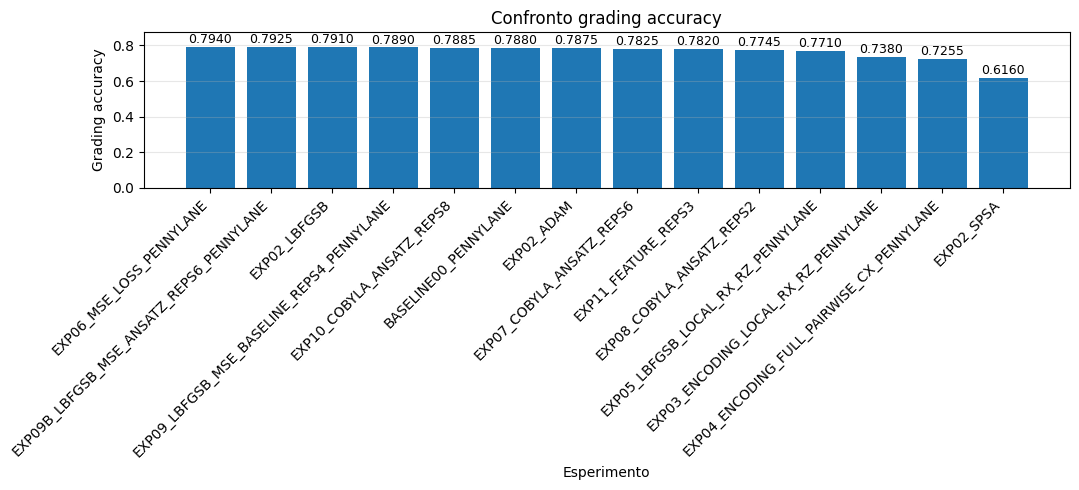

In [27]:
# ============================================================
# Final comparison plots with explicit numerical values
# ============================================================

import pandas as pd
import numpy as onp
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Controllo preliminare
# ------------------------------------------------------------

if "comparable_results_df" not in globals():
    raise NameError(
        "La variabile comparable_results_df non esiste. "
        "Esegui prima la cella che costruisce final_results_df, "
        "comparable_results_df e pending_results_df."
    )

plot_df = comparable_results_df.copy()

if plot_df.empty:
    print("Nessun risultato comparabile disponibile.")
    print("Devi prima eseguire o caricare almeno un esperimento con artefatti compatibili.")
else:
    # Conversione robusta a numerico
    plot_df["grading_accuracy"] = pd.to_numeric(
        plot_df["grading_accuracy"],
        errors="coerce"
    )

    plot_df["circuit_cost"] = pd.to_numeric(
        plot_df["circuit_cost"],
        errors="coerce"
    )

    plot_df = plot_df.dropna(subset=["grading_accuracy"]).copy()

    # Ordinamento dal migliore al peggiore
    plot_df = plot_df.sort_values(
        "grading_accuracy",
        ascending=False
    ).reset_index(drop=True)

    # ========================================================
    # 1. Tabella numerica esplicita
    # ========================================================

    columns_to_show = [
        "experiment_id",
        "experiment_type",
        "changed_factor",
        "optimizer",
        "loss",
        "grading_accuracy",
        "circuit_cost",
    ]

    columns_to_show = [col for col in columns_to_show if col in plot_df.columns]

    grading_table = plot_df[columns_to_show].copy()
    grading_table.insert(0, "ranking", range(1, len(grading_table) + 1))

    display(
        grading_table.style.format(
            {
                "grading_accuracy": "{:.4f}",
                "circuit_cost": "{:.0f}",
            }
        )
    )

    # ========================================================
    # 2. Bar plot ordinato della grading accuracy
    # ========================================================

    plt.figure(figsize=(11, 5))

    bars = plt.bar(
        plot_df["experiment_id"],
        plot_df["grading_accuracy"]
    )

    plt.ylabel("Grading accuracy")
    plt.xlabel("Esperimento")
    plt.title("Confronto grading accuracy")
    plt.xticks(rotation=45, ha="right")
    plt.grid(axis="y", alpha=0.3)

    # Valori numerici sopra le barre
    for bar, value in zip(bars, plot_df["grading_accuracy"]):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            value + 0.005,
            f"{value:.4f}",
            ha="center",
            va="bottom",
            fontsize=9,
        )

    ymax = min(1.0, float(plot_df["grading_accuracy"].max()) + 0.08)
    plt.ylim(0.0, ymax)

    plt.tight_layout()

    if "FIGURE_ROOT" in globals():
        path = FIGURE_ROOT / "grading_accuracy_barplot_numeric.png"
        plt.savefig(path, dpi=150)

    plt.show()



## 19. Grafici finali di confronto

I grafici sono generati solo sui risultati comparabili. Se la tabella è vuota, significa che bisogna prima rigenerare gli esperimenti con `RUN_TRAINING = True`.

Nota: le curve NLL e MSE sono separate perché le due loss hanno scale diverse. Una loss più bassa non implica automaticamente grading accuracy più alta.

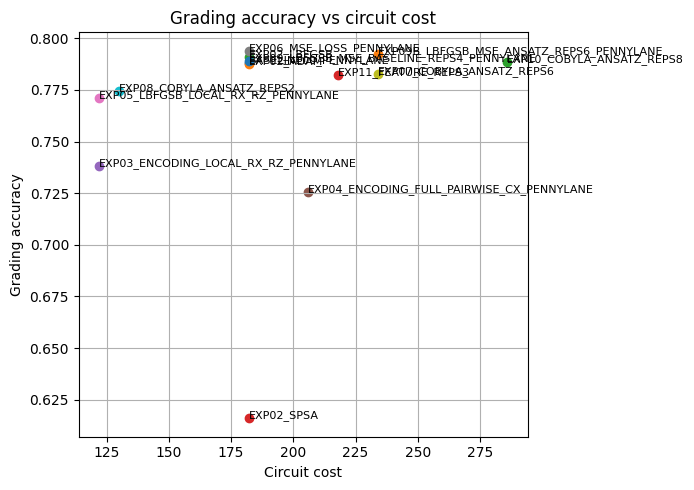

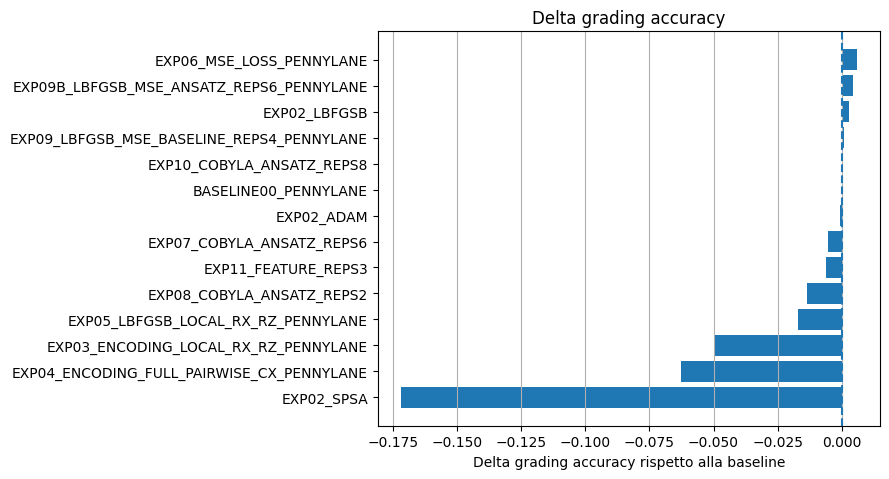

In [28]:
def plot_if_available(df):
    if df.empty:
        print("Nessun risultato comparabile disponibile. Eseguire il training o copiare artefatti compatibili.")
        return

    # 1. Grading accuracy vs circuit cost.
    plt.figure(figsize=(7, 5))
    for _, row in df.iterrows():
        plt.scatter(row["circuit_cost"], row["grading_accuracy"])
        plt.text(row["circuit_cost"], row["grading_accuracy"], row["experiment_id"], fontsize=8)
    plt.xlabel("Circuit cost")
    plt.ylabel("Grading accuracy")
    plt.title("Grading accuracy vs circuit cost")
    plt.grid(True)
    plt.tight_layout()
    path = FIGURE_ROOT / "grading_accuracy_vs_circuit_cost.png"
    plt.savefig(path, dpi=150)
    plt.show()


    # 3. Delta rispetto alla baseline.
    baseline_rows = df[df["experiment_id"] == "BASELINE00_PENNYLANE"]
    if not baseline_rows.empty:
        baseline_acc = float(baseline_rows.iloc[0]["grading_accuracy"])
        delta_df = df.copy()
        delta_df["delta_grading_accuracy"] = delta_df["grading_accuracy"].astype(float) - baseline_acc
        delta_df = delta_df.sort_values("delta_grading_accuracy")
        plt.figure(figsize=(9, max(4, 0.35 * len(delta_df))))
        plt.barh(delta_df["experiment_id"], delta_df["delta_grading_accuracy"])
        plt.axvline(0.0, linestyle="--")
        plt.xlabel("Delta grading accuracy rispetto alla baseline")
        plt.title("Delta grading accuracy")
        plt.grid(True, axis="x")
        plt.tight_layout()
        path = FIGURE_ROOT / "delta_grading_accuracy_vs_baseline.png"
        plt.savefig(path, dpi=150)
        plt.show()
    else:
        print("Baseline non presente tra i risultati comparabili: salto il delta vs baseline.")




plot_if_available(comparable_results_df)

## 20. Loss curves aggregate

Questa sezione legge le loss history dagli artefatti compatibili e separa NLL e MSE. Il confronto tra loss diverse non è quantitativamente diretto.

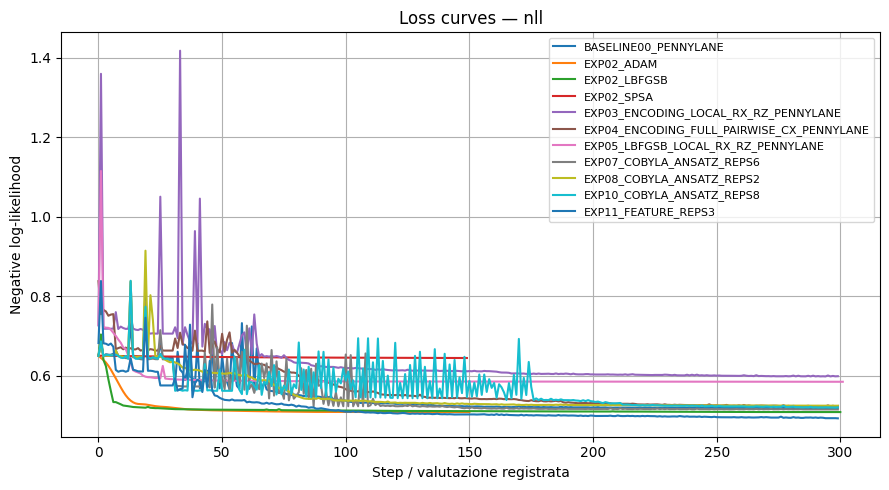

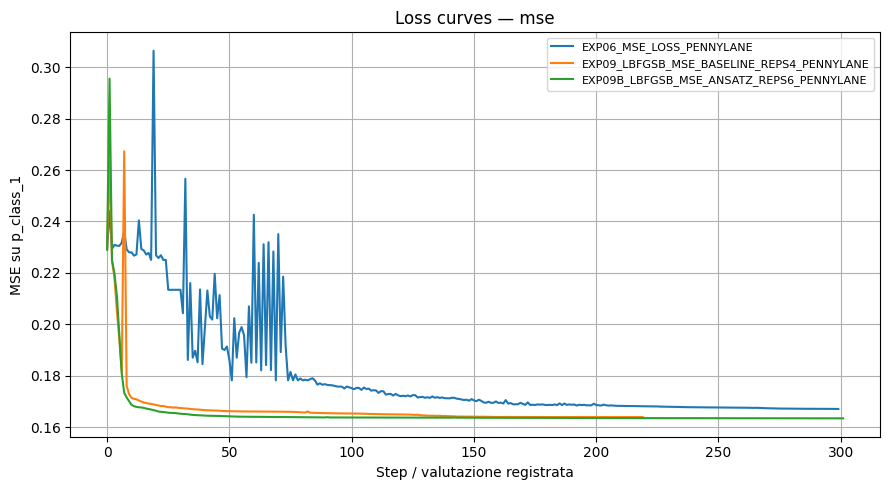

In [29]:
def plot_loss_curves_by_type(results_df, loss_type):
    subset = results_df[(results_df["is_comparable"] == True) & (results_df["loss"] == loss_type)]
    if subset.empty:
        print(f"Nessuna loss curve disponibile per loss={loss_type}.")
        return

    plt.figure(figsize=(9, 5))
    for _, row in subset.iterrows():
        exp_id = row["experiment_id"]
        history_path = ARTIFACT_ROOT / exp_id / "loss_history.npy"
        if not history_path.exists():
            continue
        history = onp.load(history_path)
        plt.plot(history, label=exp_id)

    ylabel = "Negative log-likelihood" if loss_type == "nll" else "MSE su p_class_1"
    plt.xlabel("Step / valutazione registrata")
    plt.ylabel(ylabel)
    plt.title(f"Loss curves — {loss_type}")
    plt.grid(True)
    plt.legend(fontsize=8)
    plt.tight_layout()
    path = FIGURE_ROOT / f"loss_curves_{loss_type}.png"
    plt.savefig(path, dpi=150)
    plt.show()

plot_loss_curves_by_type(final_results_df, "nll")
plot_loss_curves_by_type(final_results_df, "mse")

## 21. Baseline: confusion matrix e ROC

Se gli artefatti della baseline sono disponibili, le figure sono già salvate nella sua sottocartella. Questa cella le rigenera solo quando i pesi sono presenti.

Confusion matrix baseline:
                pred_0_digit_4  pred_1_digit_9
true_0_digit_4             775             225
true_1_digit_9             199             801
ROC AUC baseline: 0.8061


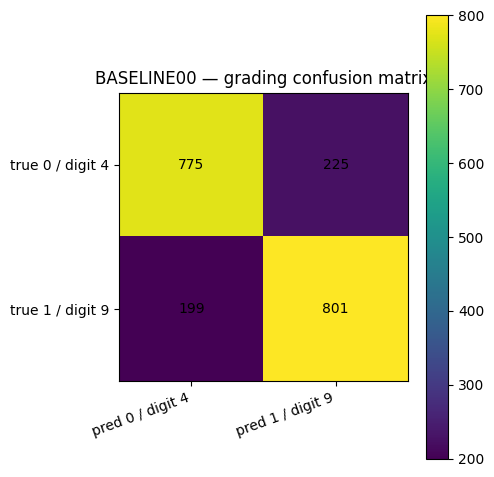

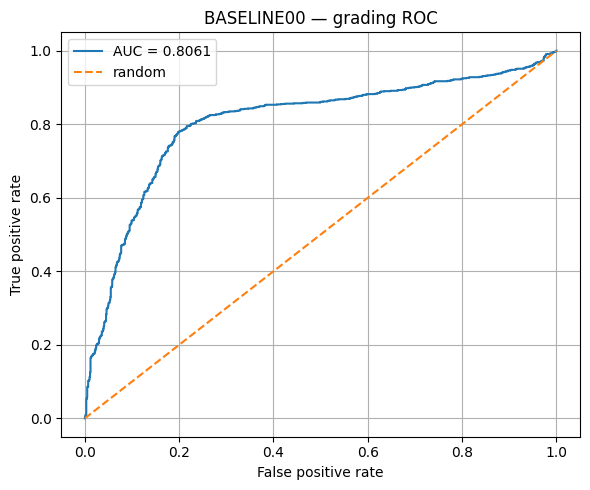

In [53]:
def regenerate_baseline_diagnostics_if_possible():
    baseline_cfg = next(e for e in EXPERIMENTS if e.experiment_id == "BASELINE00_PENNYLANE")
    paths = artifact_paths(baseline_cfg)
    if not paths["trained_flat_weights"].exists():
        print("Pesi baseline non disponibili. Eseguire la baseline per generare confusion matrix e ROC.")
        return

    circuit = make_qnode(baseline_cfg)
    flat = onp.load(paths["trained_flat_weights"])
    grading_eval = evaluate_dataset(grading_features, grading_labels, flat, baseline_cfg, circuit)
    cm = confusion_matrix_binary(grading_labels, grading_eval["y_pred"])
    fpr, tpr, thresholds, auc = roc_curve_binary(grading_labels, grading_eval["y_score"])

    print("Confusion matrix baseline:")
    print(pd.DataFrame(cm, index=["true_0_digit_4", "true_1_digit_9"], columns=["pred_0_digit_4", "pred_1_digit_9"]))
    print(f"ROC AUC baseline: {auc:.4f}")

    save_confusion_matrix_plot(cm, "BASELINE00 — grading confusion matrix", paths["confusion_matrix"])
    save_roc_plot(fpr, tpr, auc, "BASELINE00 — grading ROC", paths["roc_curve"])

regenerate_baseline_diagnostics_if_possible()

## 22. Commento critico guidato

Usare questa sezione dopo aver generato risultati comparabili.

Punti da discutere:

1. **Separabilità del dataset**: le classi non sono perfettamente separate nello spazio a tre feature. Questo limita il massimo ottenibile con qualunque classificatore basato su questa rappresentazione.
2. **Grading accuracy come metrica principale**: il test interno da 12 osservazioni è troppo piccolo per conclusioni robuste.
3. **Circuit cost**: un costo più alto non garantisce accuracy migliore. Profondità maggiore può aumentare espressività ma anche difficoltà di ottimizzazione.
4. **Loss non confrontabili direttamente**: NLL e MSE hanno scale diverse. Il confronto va fatto principalmente sulle accuracy e sulle diagnostiche, non sul valore assoluto della loss.
5. **Ottimizzatori**: se COBYLA si ferma per `MAXFUN`, `optimizer_success=False` non significa necessariamente fallimento del modello; indica che è stato raggiunto il budget. Tuttavia va riportato senza mascherarlo.
6. **Esperimenti combinati**: EXP05, EXP09 ed EXP09B non permettono attribuzione causale isolata, perché modificano più leve.
7. **Inizializzazione**: tutti i risultati finali devono essere rigenerati con `uniform[-0.05,0.05]_seed10599`. I vecchi risultati con zeri possono essere citati solo come storici/non confrontabili.

## 23. Conclusioni operative

Questo notebook sostituisce i notebook separati come punto unico di esecuzione e confronto.

Per ottenere la tabella finale definitiva:

1. verificare che `dataset_4_9.csv` sia nella cartella del notebook oppure permettere il download;
2. impostare `RUN_TRAINING = True`;
3. impostare `RETRAIN_IF_ARTIFACT_EXISTS = True` se si vogliono rigenerare anche risultati già presenti;
4. eseguire tutte le celle dall'inizio;
5. usare `final_vqc_artifacts/final_comparison_comparable_only.csv` come tabella finale coerente;
6. usare `final_vqc_artifacts/experiments_to_regenerate.csv` per verificare eventuali esperimenti ancora mancanti.

La versione finale della relazione non deve presentare nella stessa tabella risultati ottenuti con initial point nullo e risultati ottenuti con inizializzazione uniforme, salvo una colonna esplicita di status e un commento metodologico che li dichiari non confrontabili.